# Teks — Klasifikasi Teks Bahasa Inggris (tweet sentimen)
**Kapan dipakai:** teks berbahasa Inggris. Bedanya dengan teks Indonesia:
- stopword Inggris (kata negasi `not`, `no` TIDAK dibuang, penting untuk sentimen);
- kontraksi (`can't` → `can not`);
- stemming Porter (`loved`, `loving` → `love`);
- emoji diubah jadi kata (`😂` → `face_with_tears_of_joy`).

**Data demo:** TweetEval sentiment (negative / neutral / positive), `@user` sudah dianonimkan.
Model Inggris pretrained (all-MiniLM-L6-v2 / distilbert-base-uncased) ada di `pretrained/` →
pakai di `text/klasifikasi_embedding` atau `text/klasifikasi_finetune`.

In [1]:
import re

import emoji
import matplotlib.pyplot as plt
import pandas as pd
from nltk.stem import PorterStemmer
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, TfidfVectorizer
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, f1_score
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import ComplementNB
from sklearn.pipeline import make_pipeline, make_union
from sklearn.svm import LinearSVC

## Konfigurasi

In [2]:
DATA_FOLDER = "../../data_latihan/text/english"   # GANTI saat lomba
TRAIN_CSV = f"{DATA_FOLDER}/tweet_sentiment_train.csv"
TEST_CSV = f"{DATA_FOLDER}/tweet_sentiment_test.csv"
TEST_KEY_CSV = f"{DATA_FOLDER}/tweet_sentiment_test_labels.csv"   # hanya ada di data latihan

TEXT_COL = "text"
TARGET = "label"
CONTRACTIONS = {"can't": "can not", "won't": "will not", "n't": " not", "'re": " are",
                "'s": " is", "'ll": " will", "'ve": " have", "'m": " am", "'d": " would"}
STOP_WORDS = ENGLISH_STOP_WORDS - {"not", "no", "nor", "never"}
SEED = 42

## Baca data

In [3]:
train = pd.read_csv(TRAIN_CSV)
test = pd.read_csv(TEST_CSV)
train[TEXT_COL] = train[TEXT_COL].fillna("")
test[TEXT_COL] = test[TEXT_COL].fillna("")
print("train:", train.shape, "| test:", test.shape)
train.head()

train: (8000, 3) | test: (2000, 2)


,id,text,label
0,2019,"""if YoVentura had done what @user Thor did on ...",neutral
1,7366,@user I'd buy the next iPad if they had Fassbe...,positive
2,9107,New #BeautyAndTheBeast photo of Gaston wooing ...,positive
3,5443,I love me some College Football but I can't wa...,positive
4,8551,@user @user @user alt-right leaders are a pac...,negative


## EDA: kelas, emoji, hashtag, panjang tweet

label
neutral     3637
positive    2877
negative    1486
Name: count, dtype: int64


ada emoji: 0.012
ada hashtag: 0.224


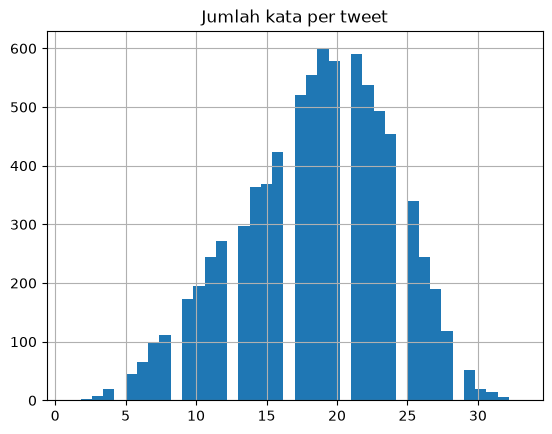

In [4]:
print(train[TARGET].value_counts())
emoji_counts = train[TEXT_COL].apply(emoji.emoji_count)
print("ada emoji:", round((emoji_counts > 0).mean(), 3))
print("ada hashtag:", round(train[TEXT_COL].str.contains("#").mean(), 3))
word_counts = train[TEXT_COL].str.split().str.len()
word_counts.hist(bins=40)
plt.title("Jumlah kata per tweet")
plt.show()

## Praproses Inggris
Urutan: emoji → kata, huruf kecil, kontraksi, buang link/mention/tanda `#`, sisakan huruf,
buang stopword, stemming.

In [5]:
stemmer = PorterStemmer()


def clean_text(text):
    text = emoji.demojize(text, delimiters=(" ", " "))
    text = text.lower()
    for short, long in CONTRACTIONS.items():
        text = text.replace(short, long)
    text = re.sub(r"http\S+|@\w+", " ", text)
    text = text.replace("#", " ")
    text = re.sub(r"[^a-z_\s]", " ", text)
    words = []
    for word in text.split():
        if word not in STOP_WORDS:
            words.append(stemmer.stem(word))
    return " ".join(words)


print(train.loc[3, TEXT_COL])
print(clean_text(train.loc[3, TEXT_COL]))

train["bersih"] = train[TEXT_COL].apply(clean_text)
test["bersih"] = test[TEXT_COL].apply(clean_text)

I love me some College Football but I can't wait to watch some Tom Brady and the Patriots play on Thursday. #NFL
love colleg footbal not wait watch tom bradi patriot play thursday nfl


## Split train / validasi

In [6]:
X_train, X_val, y_train, y_val = train_test_split(
    train["bersih"], train[TARGET], test_size=0.2, stratify=train[TARGET], random_state=SEED
)

## Model
Pilih SATU vectorizer dan SATU model: hapus `#` di baris yang ingin dipakai.

In [7]:
vectorizer = make_union(TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True),
                        TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=3,
                                        sublinear_tf=True))
# vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)

model = LogisticRegression(C=2, class_weight="balanced", max_iter=3000)
# model = LinearSVC(C=0.3, class_weight="balanced")
# model = SGDClassifier(loss="modified_huber", class_weight="balanced", random_state=SEED)
# model = ComplementNB(alpha=0.5)

pipe = make_pipeline(vectorizer, model)
pipe.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('featureunion', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](3,)","['negative','neutral','positive']"
,"transformer_list transformer_list: list of (str, transformer) tuplesList of transformer objects to be applied to the data. The firsthalf of each tuple is the name of the transformer. The transformer canbe 'drop' for it to be ignored or can be 'passthrough' for features tobe passed unchanged... versionadded:: 1.1 Added the option `""passthrough""`... versionchanged:: 0.22 Deprecated `None` as a transformer in favor of 'drop'.","[('tfidfvectorizer-1', ...), ('tfidfvectorizer-2', ...)]"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer.Keys are transformer names, values the weights.Raises ValueError if key not present in ``transformer_list``.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, default=TrueIf True, :meth:`get_feature_names_out` will prefix all feature nameswith the name of the transformer that generated that feature.If False, :meth:`get_feature_names_out` will not prefix any featurenames and will error if feature names are not unique... versionadded:: 1.5",True


## Evaluasi di validasi

F1 macro: 0.592
              precision    recall  f1-score   support

    negative       0.52      0.52      0.52       297
     neutral       0.62      0.61      0.61       728
    positive       0.64      0.65      0.65       575

    accuracy                           0.61      1600
   macro avg       0.59      0.59      0.59      1600
weighted avg       0.61      0.61      0.61      1600



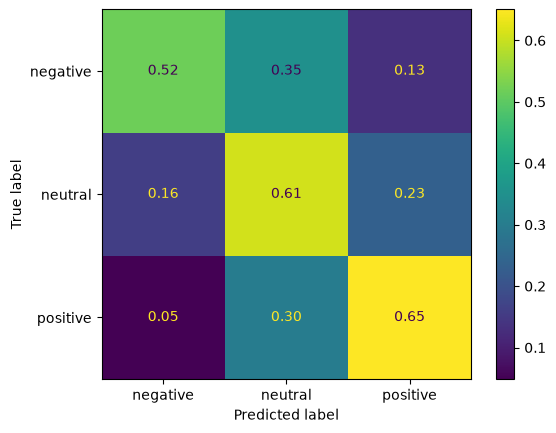

In [8]:
val_predictions = pipe.predict(X_val)
print("F1 macro:", round(f1_score(y_val, val_predictions, average="macro"), 4))
print(classification_report(y_val, val_predictions))
ConfusionMatrixDisplay.from_predictions(y_val, val_predictions, normalize="true",
                                        values_format=".2f")
plt.show()

## Latih ulang di semua data + submission

In [9]:
pipe.fit(train["bersih"], train[TARGET])
predictions = pipe.predict(test["bersih"])

submission = pd.DataFrame()
submission["id"] = test["id"]
submission["label"] = predictions
submission.to_csv("submission.csv", index=False)
submission.head()

,id,label
0,4069,neutral
1,6249,positive
2,9855,negative
3,3666,negative
4,7271,neutral


## Cek dengan kunci jawaban latihan
**HAPUS sel ini saat lomba**: file kunci hanya ada di data latihan.

In [10]:
test_key = pd.read_csv(TEST_KEY_CSV)["label"]
print("F1 macro test (kunci latihan):", round(f1_score(test_key, predictions, average="macro"), 4))

F1 macro test (kunci latihan): 0.6067
